# Model Optimization and Ablation Study

In this notebook, I performed the main steps of the machine learning pipeline for cervical cancer prediction on both the full dataset and a reduced dataset without test results. I also compared the results between these two versions and analyzed common influential features using SHAP.

### Data Preparation
Missing values were handled using KNN Imputer, which preserves relationships between features better than simple imputation.
To address class imbalance, I applied SMOTE to generate synthetic samples for the minority class.
After that, I performed basic feature engineering, including normalization of numerical features and encoding of categorical variables.

### Modeling
I implemented and compared four machine learning models:
Logistic Regression
Support Vector Machine (SVM)
Random Forest
XGBoost.
For each model, I used Grid Search to optimize hyperparameters and improve performance.

### Evaluation
Models were evaluated using Accuracy, Recall, F1-score, and ROC-AUC, with a primary focus on **Recall** due to the importance of correctly identifying positive cases.
Additionally, I used SHAP to interpret feature importance and understand how individual variables influence predictions.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [2]:
df = pd.read_csv("risk_factors_cervical_cancer.csv")

df = df.replace('?', np.nan)
df = df.apply(pd.to_numeric, errors='coerce')

X_full = df.drop("Biopsy", axis=1)
y = df["Biopsy"]

In [3]:
print(df.columns.tolist())

['Age', 'Number of sexual partners', 'First sexual intercourse', 'Num of pregnancies', 'Smokes', 'Smokes (years)', 'Smokes (packs/year)', 'Hormonal Contraceptives', 'Hormonal Contraceptives (years)', 'IUD', 'IUD (years)', 'STDs', 'STDs (number)', 'STDs:condylomatosis', 'STDs:cervical condylomatosis', 'STDs:vaginal condylomatosis', 'STDs:vulvo-perineal condylomatosis', 'STDs:syphilis', 'STDs:pelvic inflammatory disease', 'STDs:genital herpes', 'STDs:molluscum contagiosum', 'STDs:AIDS', 'STDs:HIV', 'STDs:Hepatitis B', 'STDs:HPV', 'STDs: Number of diagnosis', 'STDs: Time since first diagnosis', 'STDs: Time since last diagnosis', 'Dx:Cancer', 'Dx:CIN', 'Dx:HPV', 'Dx', 'Hinselmann', 'Schiller', 'Citology', 'Biopsy']


In [4]:
cols_to_drop = ["Schiller", "Hinselmann", "Citology", "Dx:HPV", "Dx:Cancer"]

X_reduced = df.drop(cols_to_drop + ["Biopsy"], axis=1)

In [5]:
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train_red = X_reduced.loc[X_train_full.index]
X_test_red = X_reduced.loc[X_test_full.index]

In [6]:
def run_experiment(X_train, X_test, y_train, y_test, model, param_grid):
    
    pipeline = Pipeline([
        ("imputer", KNNImputer(n_neighbors=5)),
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=42)),
        ("model", model)
    ])
    
    grid = GridSearchCV(
        pipeline,
        param_grid,
        scoring="recall",
        cv=5,
        n_jobs=-1
    )
    
    grid.fit(X_train, y_train)
    
    best_model = grid.best_estimator_
    
    y_pred = best_model.predict(X_test)
    y_prob = best_model.predict_proba(X_test)[:, 1]
    
    return {
        "Best Params": grid.best_params_,
        "Model Object": grid.best_estimator_,  
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

In [32]:
models = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, class_weight='balanced'),
        {"model__C": [0.1, 1, 10]}
    ),
    
    "Random Forest": (
        RandomForestClassifier(random_state=42, class_weight='balanced'),
        {"model__n_estimators": [100, 200],
         "model__max_depth": [3, 5, 10]}
    ),
    
    "SVM": (
        SVC(probability=True, class_weight='balanced'),
        {"model__C": [0.1, 1, 10],
         "model__kernel": ["linear", "rbf"]}
    ),
    
    "XGBoost": (
        XGBClassifier(
            eval_metric='logloss',
            scale_pos_weight = (y == 0).sum() / (y == 1).sum()
        ),
        {"model__n_estimators": [100, 200],
         "model__max_depth": [3, 5, 10]}
    )
}

In [33]:
results_full = []
results_reduced = []

for name, (model, param_grid) in models.items():
    
    print(f"Running FULL dataset: {name}")
    res_full = run_experiment(X_train_full, X_test_full, y_train, y_test, model, param_grid)
    res_full["Model"] = name
    res_full["Dataset"] = "Full"
    results_full.append(res_full)
    
    print(f"Running REDUCED dataset: {name}")
    res_red = run_experiment(X_train_red, X_test_red, y_train, y_test, model, param_grid)
    res_red["Model"] = name
    res_red["Dataset"] = "Reduced"
    results_reduced.append(res_red)

Running FULL dataset: Logistic Regression
Running REDUCED dataset: Logistic Regression
Running FULL dataset: Random Forest
Running REDUCED dataset: Random Forest
Running FULL dataset: SVM
Running REDUCED dataset: SVM
Running FULL dataset: XGBoost
Running REDUCED dataset: XGBoost


In [34]:
df_full = pd.DataFrame(results_full)
df_reduced = pd.DataFrame(results_reduced)

df_results = pd.concat([df_full, df_reduced])

df_results = df_results.sort_values(by="Recall", ascending=False)

df_results

,Best Params,Model Object,Accuracy,Precision,Recall,F1-score,ROC-AUC,Model,Dataset
0,{'model__C': 0.1},"(KNNImputer(), StandardScaler(), SMOTE(random_...",0.959302,0.642857,0.818182,0.720000,0.898927,Logistic Regression,Full
1,"{'model__max_depth': 3, 'model__n_estimators':...","(KNNImputer(), StandardScaler(), SMOTE(random_...",0.970930,0.750000,0.818182,0.782609,0.940147,Random Forest,Full
2,"{'model__C': 0.1, 'model__kernel': 'rbf'}","(KNNImputer(), StandardScaler(), SMOTE(random_...",0.936047,0.500000,0.818182,0.620690,0.957086,SVM,Full
3,"{'model__max_depth': 3, 'model__n_estimators':...","(KNNImputer(), StandardScaler(), SMOTE(random_...",0.965116,0.777778,0.636364,0.700000,0.969509,XGBoost,Full
3,"{'model__max_depth': 3, 'model__n_estimators':...","(KNNImputer(), StandardScaler(), SMOTE(random_...",0.819767,0.166667,0.454545,0.243902,0.691700,XGBoost,Reduced
0,{'model__C': 0.1},"(KNNImputer(), StandardScaler(), SMOTE(random_...",0.744186,0.097561,0.363636,0.153846,0.614907,Logistic Regression,Reduced
1,"{'model__max_depth': 3, 'model__n_estimators':...","(KNNImputer(), StandardScaler(), SMOTE(random_...",0.720930,0.088889,0.363636,0.142857,0.617165,Random Forest,Reduced
2,"{'model__C': 0.1, 'model__kernel': 'rbf'}","(KNNImputer(), StandardScaler(), SMOTE(random_...",0.796512,0.100000,0.272727,0.146341,0.627894,SVM,Reduced


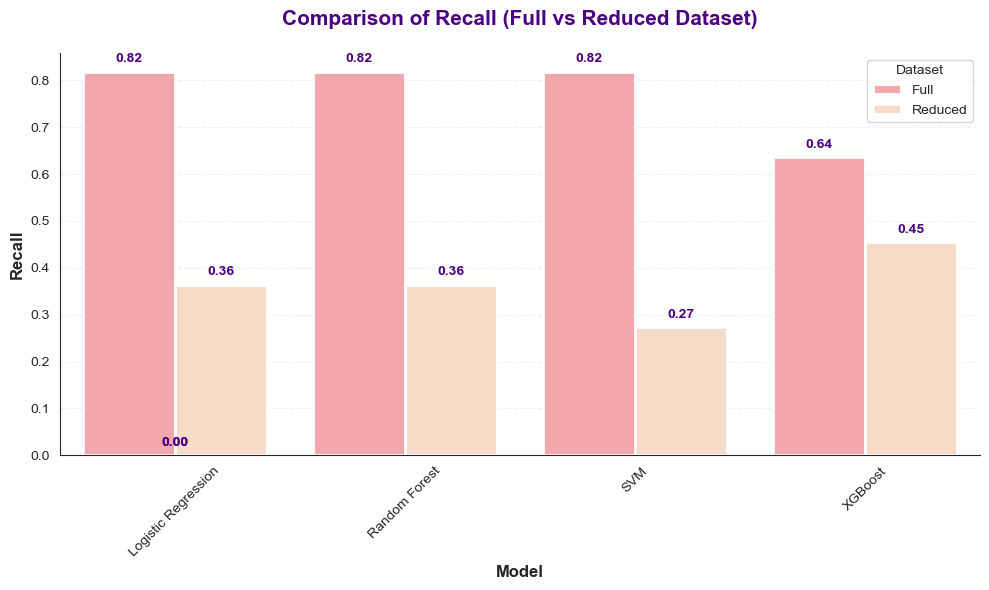

In [35]:
sns.set_style("white") 
plt.figure(figsize=(10, 6))

girly_palette = ["#FF9AA2", "#FFDAC1"]

ax = sns.barplot(
    data=df_results,
    x="Model",
    y="Recall",
    hue="Dataset",
    palette=girly_palette,
    edgecolor="#FFFFFF", 
    linewidth=2
)

plt.title("Comparison of Recall (Full vs Reduced Dataset)", 
          fontsize=15, fontweight='bold', pad=20, color='#4B0082')

plt.ylabel("Recall", fontsize=12, fontweight='bold')
plt.xlabel("Model", fontsize=12, fontweight='bold')

plt.xticks(rotation=45)

for p in ax.patches:
    ax.annotate(format(p.get_height(), '.2f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points',
                fontsize=10, fontweight='bold', color='#4B0082')

sns.despine()

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()


Running SHAP for: Logistic Regression (FULL DATASET)


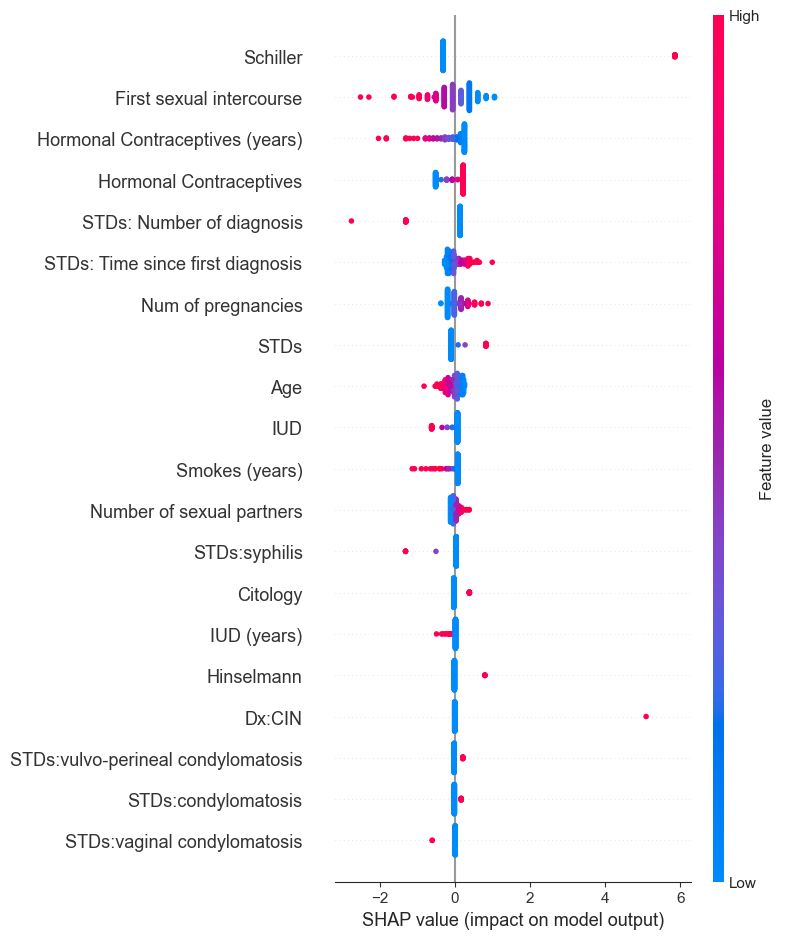

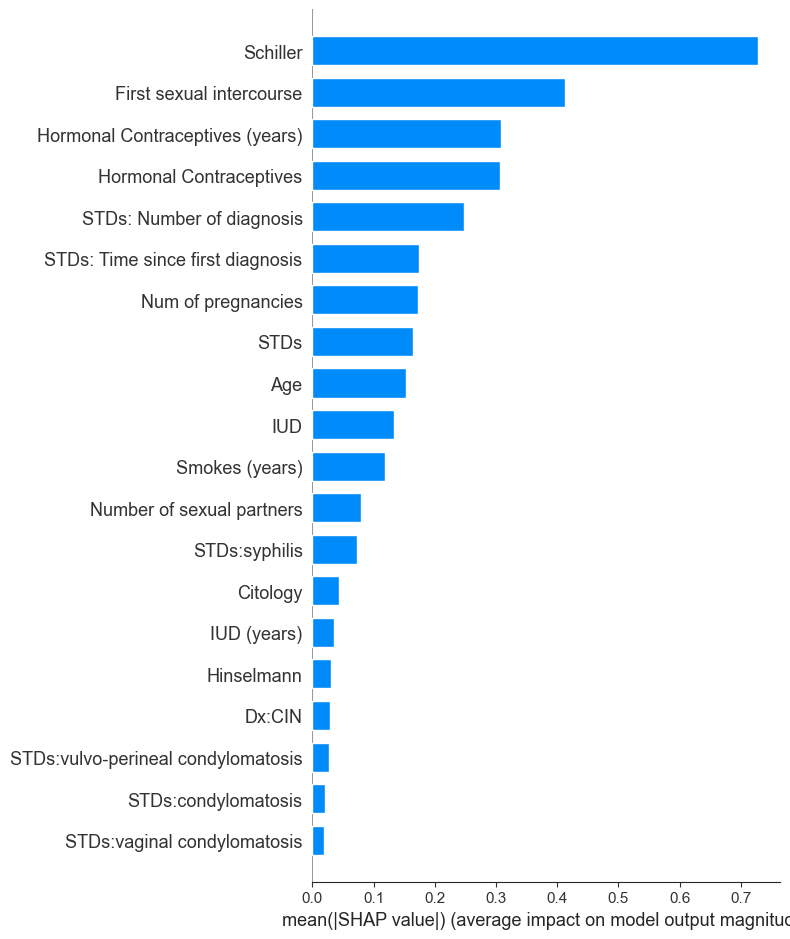


Running SHAP for: Logistic Regression (FULL DATASET)


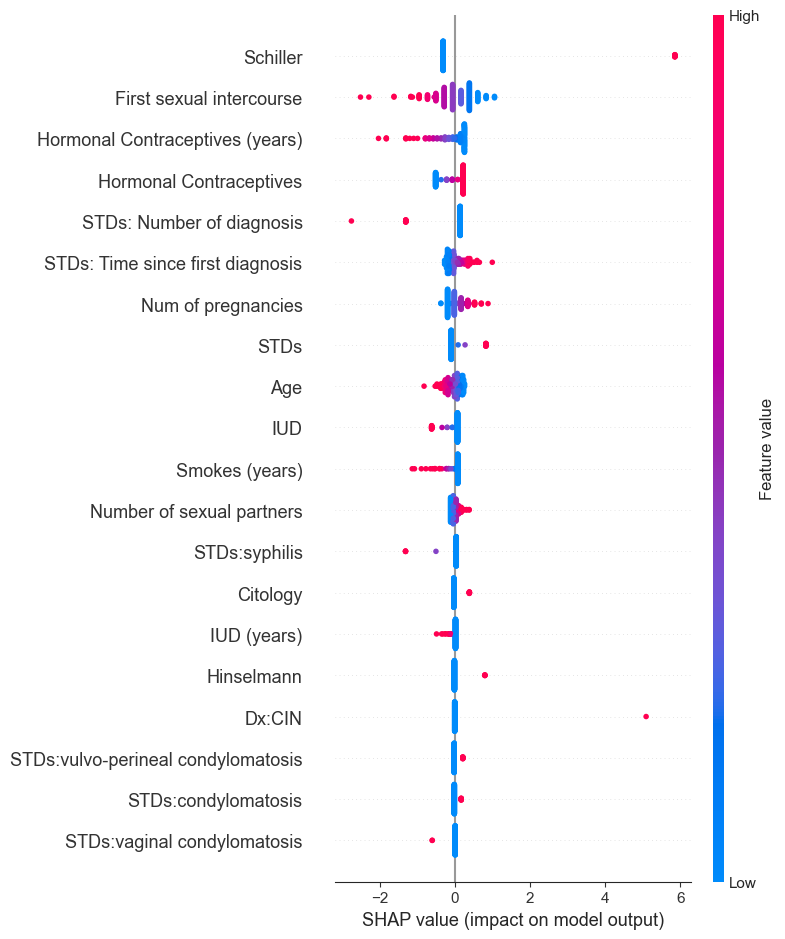

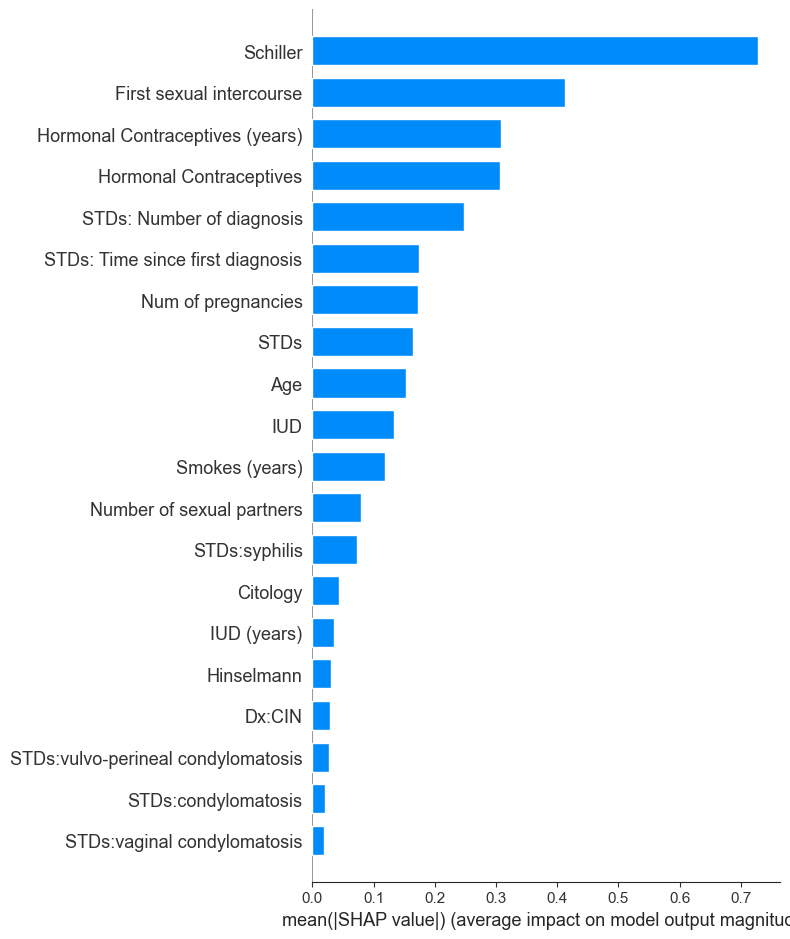


Running SHAP for: XGBoost (REDUCED DATASET)


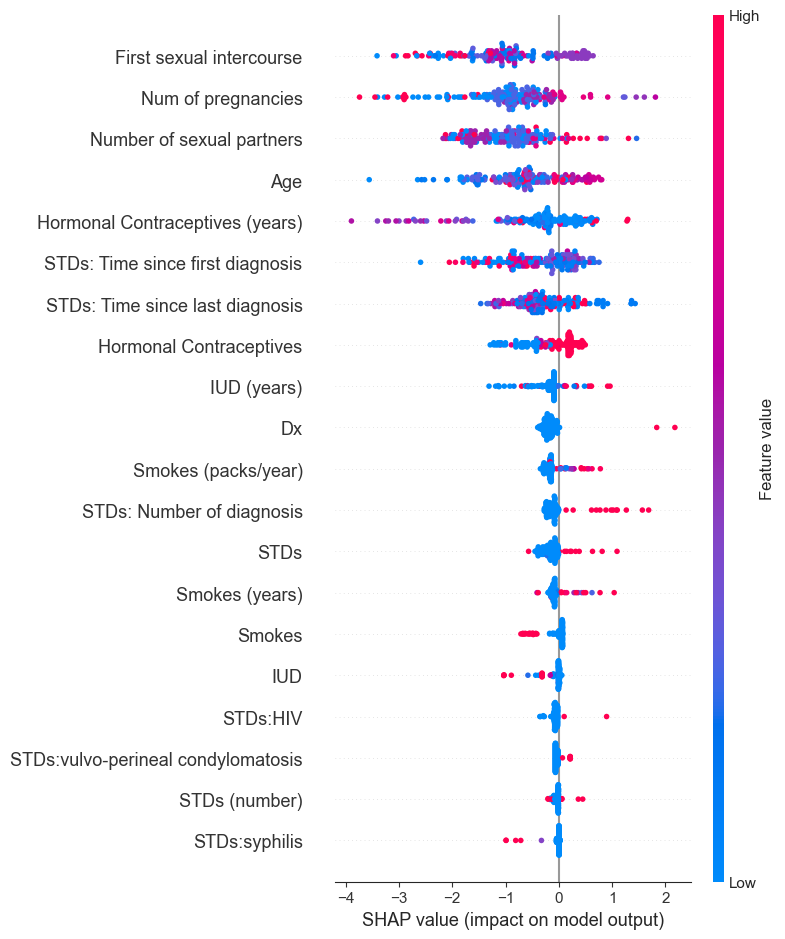

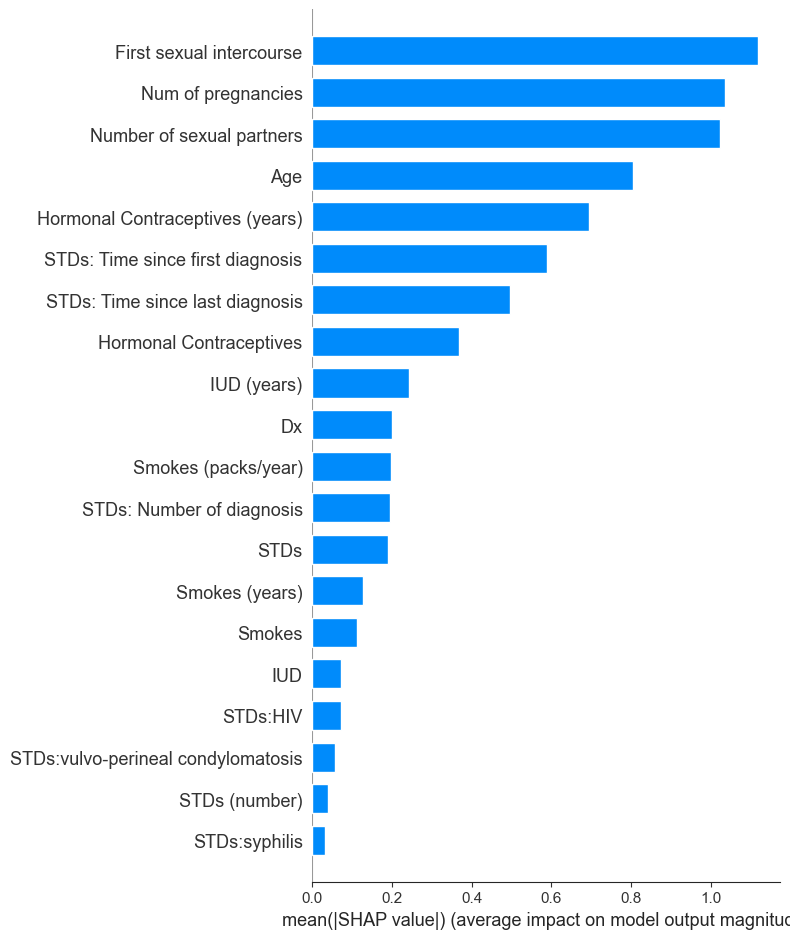

In [37]:
import shap

def run_shap_analysis(best_row, X_test_full, X_test_red):
    
    best_model = best_row["Model Object"]
    model = best_model.named_steps["model"]
    
    if best_row["Dataset"] == "Full":
        X_sample = X_test_full
        dataset_name = "FULL DATASET"
    else:
        X_sample = X_test_red
        dataset_name = "REDUCED DATASET"
    
    print(f"\nRunning SHAP for: {best_row['Model']} ({dataset_name})")
    
    X_processed = best_model.named_steps["imputer"].transform(X_sample)
    X_processed = best_model.named_steps["scaler"].transform(X_processed)
    
    if isinstance(model, LogisticRegression):
        explainer = shap.LinearExplainer(model, X_processed)
        shap_values = explainer.shap_values(X_processed)
    
    elif isinstance(model, (RandomForestClassifier, XGBClassifier)):
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_processed)
        
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
    
    else:
        explainer = shap.Explainer(model, X_processed)
        shap_values = explainer(X_processed)
    
    shap.summary_plot(
        shap_values,
        X_processed,
        feature_names=X_sample.columns
    )
    
    shap.summary_plot(
        shap_values,
        X_processed,
        feature_names=X_sample.columns,
        plot_type="bar"
    )


# === 1. The Overall Best Performing Model ===
best_overall = df_results.sort_values(by="Recall", ascending=False).iloc[0]

run_shap_analysis(best_overall, X_test_full, X_test_red)


# === 2. Best Performing Model for the Full Dataset ===
best_full = df_results[df_results["Dataset"] == "Full"] \
    .sort_values(by="Recall", ascending=False).iloc[0]

run_shap_analysis(best_full, X_test_full, X_test_red)


# === 3. Best Performing Model for the Reduced Dataset ===
best_reduced = df_results[df_results["Dataset"] == "Reduced"] \
    .sort_values(by="Recall", ascending=False).iloc[0]

run_shap_analysis(best_reduced, X_test_full, X_test_red)

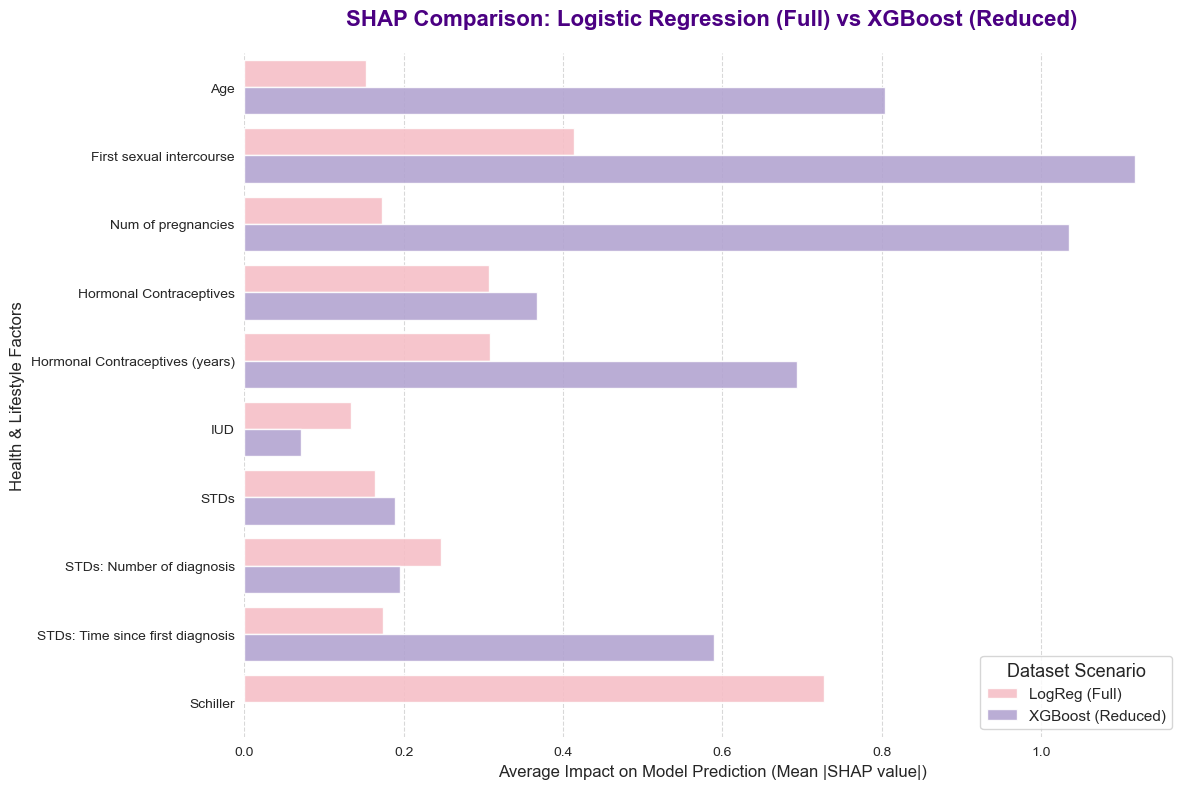

In [44]:
# === SHAP COMPARISON: Logistic Regression (FULL) vs XGBoost (REDUCED) ===

lr_full = None
xgb_red = None

for row in results_full:
    if row["Model"] == "Logistic Regression":
        lr_full = row["Model Object"]

for row in results_reduced:
    if row["Model"] == "XGBoost":
        xgb_red = row["Model Object"]

def get_shap_importance(pipeline, X, model_type):
    
    model = pipeline.named_steps["model"]
    
    X_proc = pipeline.named_steps["imputer"].transform(X)
    X_proc = pipeline.named_steps["scaler"].transform(X_proc)
    
    if model_type == "linear":
        explainer = shap.LinearExplainer(model, X_proc)
        shap_values = explainer.shap_values(X_proc)
    
    elif model_type == "tree":
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_proc)
        
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
    
    importance = np.abs(shap_values).mean(axis=0)
    
    return pd.DataFrame({
        "feature": X.columns,
        "importance": importance
    })


df_lr_full = get_shap_importance(lr_full, X_test_full, "linear")
df_lr_full["Model"] = "LogReg (Full)"

df_xgb_red = get_shap_importance(xgb_red, X_test_red, "tree")
df_xgb_red["Model"] = "XGBoost (Reduced)"


df_compare = pd.concat([df_lr_full, df_xgb_red])

top_features = (
    df_lr_full.sort_values(by="importance", ascending=False)
    .head(10)["feature"]
)

df_compare = df_compare[df_compare["feature"].isin(top_features)]

sns.set_style("whitegrid")
plt.figure(figsize=(12, 8))

girly_palette = ["#FFB6C1", "#B19CD9"] 

sns.barplot(
    data=df_compare,
    x="importance",
    y="feature",
    hue="Model",
    palette=girly_palette,
    edgecolor="white", 
    alpha=0.9
)
plt.title("SHAP Comparison: Logistic Regression (Full) vs XGBoost (Reduced)", 
          fontsize=16, pad=20, fontweight='bold', color='#4B0082')

plt.xlabel("Average Impact on Model Prediction (Mean |SHAP value|)", fontsize=12)
plt.ylabel("Health & Lifestyle Factors", fontsize=12)
plt.legend(title="Dataset Scenario", title_fontsize='13', fontsize='11', loc='lower right')
sns.despine(left=True, bottom=True)
plt.grid(axis='x', linestyle='--', alpha=0.3, color='gray')

plt.tight_layout()
plt.savefig('missing_values_plot.png', dpi=300, bbox_inches='tight')
plt.show()